# 02. Calibration at tipoff

**Question.** Are Kalshi's home-win prices at tipoff well calibrated? In other words, do home teams priced at p win about p of the time?

**Plan.** This notebook follows `ANALYSIS_PLAN.md` sections 1 to 3: the sample (section 1), the four tests (sections 2.1 to 2.4) and the block bootstrap by game date (section 3). All tests are two-sided at the 0.05 level.

**Data.** `data/processed/snapshots.csv`, main sample at horizon 0. Price `p_home`, outcome `home_win`.

**Seed.** The bootstrap uses seed 4981 and 2,000 replicates, as in the plan.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from IPython.display import display

from calibration import (RESULTS_DIR, add_bootstrap_intervals, block_bootstrap,
                         bootstrap_summary, calibration_bins, calibration_plot, load_sample,
                         logistic_table, point_estimates)
from csv_io import write_csv
from stats_tools import B, SEED, brier, fit_logit, lr_test

RESULTS_DIR.mkdir(exist_ok=True)
print(f"Bootstrap: B = {B:,}, seed = {SEED}")

Bootstrap: B = 2,000, seed = 4981


## 1. Sample

In [2]:
d = load_sample()
n_dates, n_clusters = d["game_date"].nunique(), d["home_team"].nunique()
print(f"{len(d):,} games, {n_dates} game dates, {n_clusters} home teams")
print(f"p_home from {d['p_home'].min():.3f} to {d['p_home'].max():.3f}")

1,229 games, 164 game dates, 30 home teams
p_home from 0.035 to 0.975


The sample is 1,229 games on 164 dates, with 30 home teams. No row has a missing price, so none is dropped. The prices stay strictly between 0 and 1, so the logit is finite for every game.

## 2.1 Calibration bins

Games are sorted by price and split into 10 bins of equal size. For each bin, the table compares the mean price with the share of games the home team won, with a 95% Wilson interval for that share.

In [3]:
bins = calibration_bins(d)
display(bins.round(4))

,bin,n,p_min,p_max,mean_p,home_wins,win_rate,wilson_lo,wilson_hi
0,1,123,0.0350,0.225,0.1521,18,0.1463,0.0946,0.2195
1,2,123,0.2250,0.335,0.2878,35,0.2846,0.2123,0.3699
2,3,123,0.3350,0.415,0.3783,47,0.3821,0.3010,0.4703
3,4,123,0.4150,0.485,0.4508,63,0.5122,0.4248,0.5988
4,5,123,0.4850,0.565,0.5277,59,0.4797,0.3933,0.5672
5,6,123,0.5650,0.635,0.5992,72,0.5854,0.4970,0.6686
6,7,123,0.6350,0.705,0.6690,92,0.7480,0.6645,0.8164
7,8,123,0.7050,0.775,0.7367,89,0.7236,0.6387,0.7949
8,9,123,0.7750,0.845,0.8093,96,0.7805,0.6995,0.8445
9,10,122,0.8465,0.975,0.8928,111,0.9098,0.8457,0.9489


Nine bins hold 123 games and one holds 122. In every bin, the mean price lies inside the 95% Wilson interval of the observed win rate.

The largest gaps between win rate and mean price are in bin 7 (win rate 0.748, mean price 0.669) and bin 4 (0.512 against 0.451). Bin 5 has a lower win rate (0.480) than bin 4, although its prices are higher. The intervals are 0.10 to 0.17 wide, so one bin of about 123 games cannot pin its win rate down more closely than that.

## 2.2 Brier score against a constant baseline

The Brier score is the average squared gap between price and outcome. Lower is better. The baseline is a forecast that gives every game the same probability, the overall home-win rate.

In [4]:
bs = brier(d["p_home"], d["home_win"])
write_csv(pd.DataFrame([bs]), RESULTS_DIR / "brier.csv")
display(pd.DataFrame([bs]).round(5))

,n,home_win_rate,brier,brier_baseline,brier_diff,brier_skill
0,1229,0.55492,0.19433,0.24698,-0.05265,0.21318


Home teams won 55.5% of the games. The Brier score of the prices is 0.1943, against 0.2470 for the constant baseline. The difference is -0.0527, a skill score of 0.213: the prices' Brier score is about 21% lower than the baseline's.

## 2.3 Logistic recalibration

The model is logit P(home win) = a + b · logit(p). Perfect calibration means a = 0 and b = 1. Standard errors are clustered by home team.

In [5]:
fit = fit_logit(d["p_home"], d["home_win"], groups=d["home_team"])
logi = logistic_table(fit, n_clusters)
write_csv(logi, RESULTS_DIR / "logistic.csv")
display(logi.round(4))

,term,estimate,se_cluster,ci_lo,ci_hi,null_value,z,p_value,n,n_clusters
0,intercept_a,0.0189,0.0432,-0.0657,0.1035,0.0,0.4379,0.6615,1229,30
1,slope_b,1.0352,0.0616,0.9144,1.1559,1.0,0.5708,0.5681,1229,30


The intercept is a = 0.019 (clustered SE 0.043), and the test of a = 0 gives p = 0.66. The slope is b = 1.035 (SE 0.062), and the test of b = 1 gives p = 0.57. The 95% interval for a, -0.066 to 0.104, contains 0. The interval for b, 0.914 to 1.156, contains 1. Neither test rejects at the 0.05 level.

## 2.4 Likelihood ratio test of a = 0 and b = 1

This tests both restrictions at once. It compares the log-likelihood of the prices taken as they are with that of the fitted model in 2.3.

In [6]:
lr = lr_test(d["p_home"], d["home_win"])
write_csv(pd.DataFrame([lr]), RESULTS_DIR / "lr_test.csv")
display(pd.DataFrame([lr]).round(4))

,ll_restricted,ll_unrestricted,lr_stat,df,p_value
0,-699.7334,-699.5386,0.3898,2,0.8229


The LR statistic is 0.390 on 2 degrees of freedom, p = 0.82. The test does not reject a = 0 and b = 1 together. Fitting a and b raises the log-likelihood by only 0.19 over the raw prices.

This test treats games as independent. Section 3 checks that with a bootstrap by date.

## Calibration plot

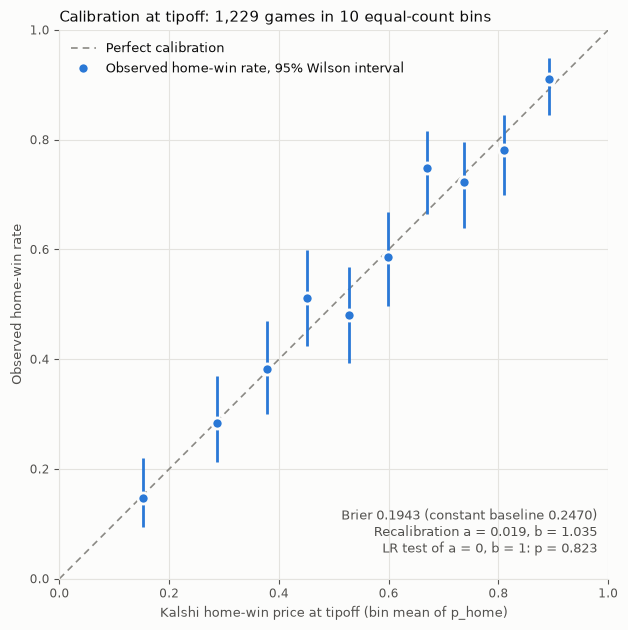

In [7]:
fig = calibration_plot(bins, bs, lr, logi, RESULTS_DIR / "calibration_plot.png")

Each point is one bin: mean price on the horizontal axis, observed home-win rate on the vertical axis, with its 95% Wilson interval. The dashed line is perfect calibration. Every interval crosses the line.

## 3. Robustness: block bootstrap by game date

Games on the same date may not be independent. Each replicate draws 164 whole dates with replacement and recomputes every statistic above. The bin edges stay fixed at their full-sample values. The table gives 95% percentile intervals from 2,000 replicates.

In [8]:
boot = block_bootstrap(d)
summary = bootstrap_summary(boot, point_estimates(bs, fit, lr, bins), n_dates)
bins = add_bootstrap_intervals(bins, summary)
write_csv(summary, RESULTS_DIR / "bootstrap_summary.csv")
write_csv(bins, RESULTS_DIR / "calibration_bins.csv")
display(summary.round(4))

,statistic,estimate,boot_mean,boot_se,boot_lo,boot_hi,B,n_dates,seed
0,brier,0.1943,0.1940,0.0054,0.1835,0.2047,2000,164,4981
1,brier_baseline,0.2470,0.2467,0.0015,0.2433,0.2491,2000,164,4981
2,brier_diff,-0.0527,-0.0527,0.0054,-0.0632,-0.0421,2000,164,4981
3,brier_skill,0.2132,0.2135,0.0218,0.1707,0.2560,2000,164,4981
4,intercept_a,0.0189,0.0220,0.0594,-0.0907,0.1386,2000,164,4981
5,slope_b,1.0352,1.0402,0.0703,0.9079,1.1817,2000,164,4981
6,lr_stat,0.3898,2.2274,2.1908,0.0639,8.0794,2000,164,4981
7,bin1_win_rate,0.1463,0.1467,0.0318,0.0853,0.2105,2000,164,4981
8,bin2_win_rate,0.2846,0.2834,0.0410,0.2039,0.3643,2000,164,4981
9,bin3_win_rate,0.3821,0.3825,0.0437,0.2975,0.4661,2000,164,4981


The plan calls a conclusion robust when the bootstrap interval agrees with the main test.

- **Intercept a.** The bootstrap interval is -0.091 to 0.139 and contains 0. The clustered interval in 2.3 also contains 0. They agree.
- **Slope b.** The bootstrap interval is 0.908 to 1.182 and contains 1. The clustered interval in 2.3 also contains 1. They agree.
- **Brier difference.** The bootstrap interval is -0.063 to -0.042 and does not contain 0. The prices score better than the constant baseline in the main result and across the bootstrap replicates.

The bootstrap standard errors (0.059 for a, 0.070 for b) are larger than the clustered ones (0.043 and 0.062).

The saved `calibration_bins.csv` adds each bin's bootstrap interval for the win rate (`boot_lo`, `boot_hi`) to the table in 2.1.

In [9]:
display(bins.round(4))

,bin,n,p_min,p_max,mean_p,home_wins,win_rate,wilson_lo,wilson_hi,boot_lo,boot_hi
0,1,123,0.0350,0.225,0.1521,18,0.1463,0.0946,0.2195,0.0853,0.2105
1,2,123,0.2250,0.335,0.2878,35,0.2846,0.2123,0.3699,0.2039,0.3643
2,3,123,0.3350,0.415,0.3783,47,0.3821,0.3010,0.4703,0.2975,0.4661
3,4,123,0.4150,0.485,0.4508,63,0.5122,0.4248,0.5988,0.4310,0.5982
4,5,123,0.4850,0.565,0.5277,59,0.4797,0.3933,0.5672,0.4000,0.5620
5,6,123,0.5650,0.635,0.5992,72,0.5854,0.4970,0.6686,0.5041,0.6667
6,7,123,0.6350,0.705,0.6690,92,0.7480,0.6645,0.8164,0.6695,0.8261
7,8,123,0.7050,0.775,0.7367,89,0.7236,0.6387,0.7949,0.6491,0.8017
8,9,123,0.7750,0.845,0.8093,96,0.7805,0.6995,0.8445,0.7068,0.8585
9,10,122,0.8465,0.975,0.8928,111,0.9098,0.8457,0.9489,0.8496,0.9593


BOOTNine bins hold 123 games and one holds 122. In every bin, the mean price lies inside the 95% Wilson interval of the observed win rate.

The largest gaps between win rate and mean price are in bin 7 (win rate 0.748, mean price 0.669) and bin 4 (0.512 against 0.451). Bin 5 has a lower win rate (0.480) than bin 4, although its prices are higher. The intervals are 0.10 to 0.17 wide, so one bin of about 123 games cannot pin its win rate down more closely than that.